In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('merged_cleaned_FE_data_v2.csv').drop_duplicates()

In [4]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up a...,2,2,2,5.0,NaN,Relatively New,567.0,556.0,500.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,8.0,West,Moderately Old,NaN,NaN,2400.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,3,3+,17.0,South-East,Relatively New,1930.0,1700.0,1500.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up...,3,3,3+,7.0,South,Old Property,2000.0,1900.0,1800.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,15.0,North,Relatively New,NaN,NaN,1326.0,0,0,0,0,0,1,44,8


In [5]:
df.shape

(3677, 24)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\4283571936.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price'])


<Axes: xlabel='price', ylabel='Density'>

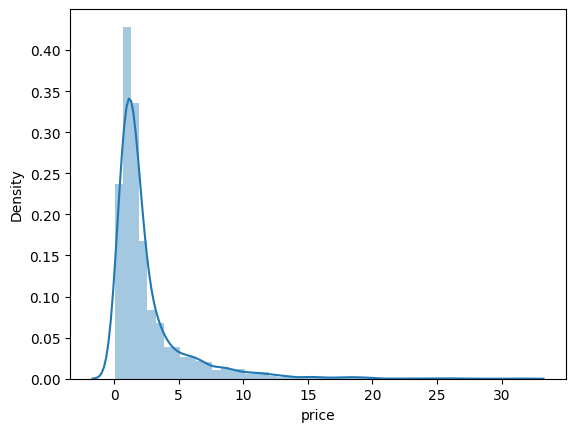

In [6]:
# strating with price column
sns.distplot(df['price'])

<Axes: xlabel='price'>

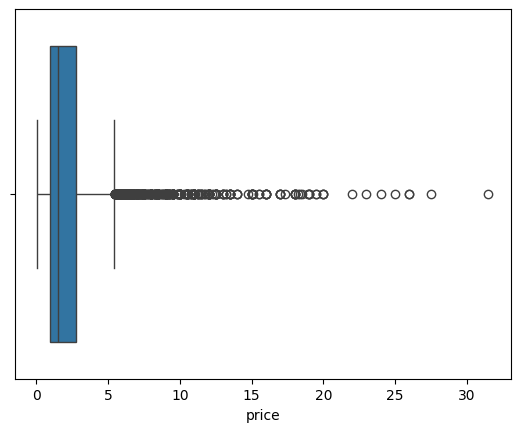

In [7]:
sns.boxplot(x=df['price'])

In [8]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
num_outliers = outliers.shape[0]
outliers_price_stats = outliers['price'].describe()

In [9]:
num_outliers, outliers_price_stats

(425,
 count    425.000000
 mean       9.235624
 std        4.065259
 min        5.460000
 25%        6.460000
 50%        8.000000
 75%       10.750000
 max       31.500000
 Name: price, dtype: float64)

In [10]:
outliers.sort_values('price',ascending=False).head(15)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
1902,house,arjun marg/ sector- 26 phase- 1/ golf course road,sector 26,31.5,35000.0,9000.0,Plot area 1000(836.13 sq.m.),7,9,3+,3.0,North-East,Moderately Old,NaN,9000.0,NaN,1,1,1,1,0,1,74,46
1747,house,independent,sector 43,27.5,24366.0,11286.0,Plot area 1254(1048.5 sq.m.),6,7,3+,3.0,North-East,Relatively New,NaN,11286.0,NaN,1,1,1,0,1,1,42,47
2271,house,independent,sector 26,26.0,82540.0,3150.0,Plot area 402(336.12 sq.m.)Built Up area: 400 ...,16,16,3+,4.0,North-West,New Property,NaN,400.0,350.0,1,1,1,1,0,1,72,46
1998,house,dlf city plots,sector 26,26.0,57206.0,4545.0,Plot area 505(422.24 sq.m.),6,7,3+,2.0,North-East,New Property,NaN,4545.0,NaN,1,1,1,0,1,1,138,8
1254,house,suncity township,sector 54,25.0,31111.0,8036.0,Plot area 1000(836.13 sq.m.),4,4,3+,2.0,North,Moderately Old,NaN,1000.0,NaN,1,1,1,1,0,0,0,48
1766,house,emaar the palm springs,sector 54,24.0,600000.0,400.0,Plot area 400(37.16 sq.m.),5,5,2,1.0,North-East,Old Property,NaN,400.0,NaN,1,1,1,0,0,0,122,9
724,house,independent,sector 26,23.0,25556.0,9000.0,Plot area 1000(836.13 sq.m.),4,4,3+,2.0,South-West,Relatively New,NaN,9000.0,NaN,1,1,1,1,0,1,145,46
1402,house,vipul tatvam villa,sector 48,22.0,26667.0,8250.0,Plot area 1000(836.13 sq.m.),5,6,3,3.0,NaN,Moderately Old,NaN,1000.0,NaN,0,0,1,0,0,0,54,15
3591,house,luxury dlf city floors,sector 26,20.0,48889.0,4091.0,Plot area 500(418.06 sq.m.),16,16,3+,4.0,NaN,New Property,NaN,500.0,NaN,0,0,1,0,0,1,31,47
1741,house,dlf city plots,sector 26,20.0,44265.0,4518.0,Plot area 502(419.74 sq.m.),16,20,3+,4.0,North-East,New Property,NaN,4518.0,NaN,1,1,1,1,0,1,153,8


In [11]:
# on price column we have some genuine outliers and as well as some data errors also

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\2952966830.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

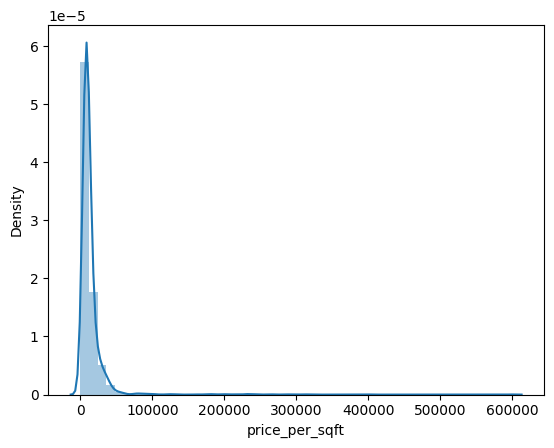

In [12]:
# price_per_sqft
sns.distplot(df['price_per_sqft'])

<Axes: xlabel='price_per_sqft'>

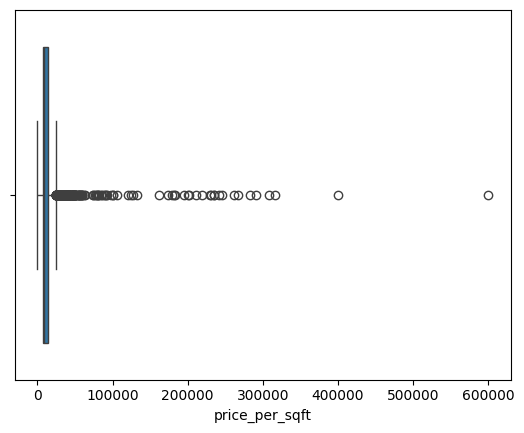

In [13]:
sns.boxplot(x=df['price_per_sqft'])


In [14]:
Q1 = df['price_per_sqft'].quantile(0.25)
Q3 = df['price_per_sqft'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_sqft = df[(df['price_per_sqft'] < lower_bound) | (df['price_per_sqft'] > upper_bound)]

num_outliers = outliers_sqft.shape[0]
outliers_sqft_stats = outliers_sqft['price_per_sqft'].describe()

num_outliers, outliers_sqft_stats

(352,
 count       352.000000
 mean      52740.403409
 std       61292.606222
 min       24500.000000
 25%       28224.750000
 50%       33498.000000
 75%       42037.500000
 max      600000.000000
 Name: price_per_sqft, dtype: float64)

In [15]:
outliers_sqft['area'] = outliers_sqft['area'].apply(lambda x:x*9 if x<1000 else x)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\205471443.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_sqft['area'] = outliers_sqft['area'].apply(lambda x:x*9 if x<1000 else x)


In [16]:
outliers_sqft['price_per_sqft'] = round((outliers_sqft['price']*10000000)/outliers_sqft['area'])

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\3686006548.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_sqft['price_per_sqft'] = round((outliers_sqft['price']*10000000)/outliers_sqft['area'])


In [17]:
outliers_sqft['price_per_sqft'].describe()

count      352.000000
mean     29446.088068
std      12356.621693
min       2723.000000
25%      25602.500000
50%      29880.000000
75%      35602.250000
max      82540.000000
Name: price_per_sqft, dtype: float64

In [18]:
df.update(outliers_sqft)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\2186227091.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

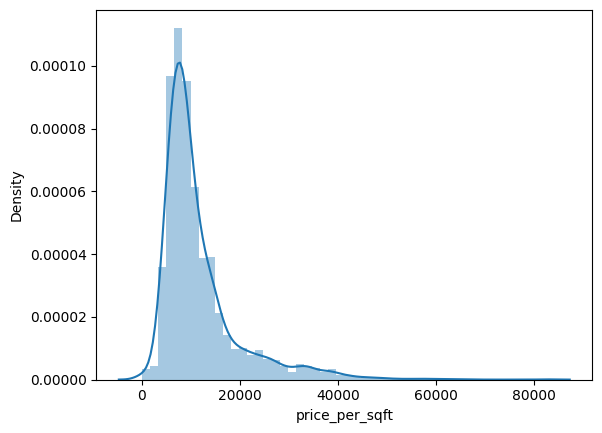

In [19]:
sns.distplot(df['price_per_sqft'])

<Axes: xlabel='price_per_sqft'>

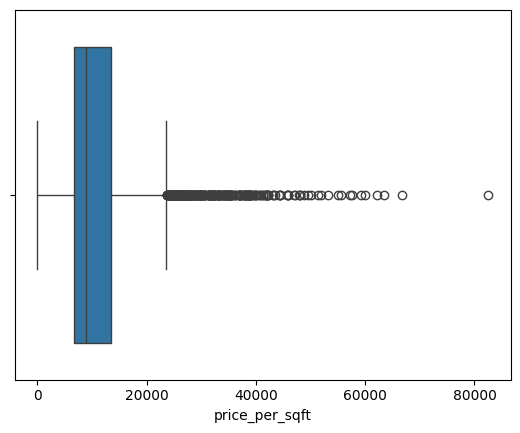

In [20]:
sns.boxplot(x=df['price_per_sqft'])

In [21]:
df[df['price_per_sqft']>50000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
679,house,project housing board colony,sector 31,8.00,63492.0,1260.0,Built Up area: 140 (117.06 sq.m.),2,1,0,1.0,NaN,Undefined,NaN,140.0,NaN,0,0,0,0,0,0,0,49
834,house,cloudnine cottages,sohna road road,5.50,55000.0,1000.0,Plot area 1000(92.9 sq.m.),3,3,0,1.0,NaN,Moderately Old,NaN,1000.0,NaN,0,0,0,0,0,0,0,47
1339,house,independent,sector 25,16.00,59259.0,2700.0,Plot area 350(292.64 sq.m.)Built Up area: 325 ...,16,16,3+,4.0,West,New Property,NaN,325.0,300.0,1,1,1,1,0,1,72,44
1482,house,emaar mgf marbella,sector 66,18.00,55556.0,3240.0,Plot area 360(301.01 sq.m.),4,4,3+,3.0,East,Moderately Old,NaN,3240.0,NaN,1,1,1,0,0,1,75,14
1766,house,emaar the palm springs,sector 54,24.00,66667.0,3600.0,Plot area 400(37.16 sq.m.),5,5,2,1.0,North-East,Old Property,NaN,400.0,NaN,1,1,1,0,0,0,122,9
1998,house,dlf city plots,sector 26,26.00,57206.0,4545.0,Plot area 505(422.24 sq.m.),6,7,3+,2.0,North-East,New Property,NaN,4545.0,NaN,1,1,1,0,1,1,138,8
2000,house,nul,sector 28,12.50,51440.0,2430.0,Plot area 270(225.75 sq.m.),16,17,3+,4.0,South,Relatively New,NaN,2430.0,NaN,1,1,1,0,1,1,137,47
2271,house,independent,sector 26,26.00,82540.0,3150.0,Plot area 402(336.12 sq.m.)Built Up area: 400 ...,16,16,3+,4.0,North-West,New Property,NaN,400.0,350.0,1,1,1,1,0,1,72,46
2375,house,independent,sector 26,14.75,51864.0,2844.0,Plot area 316(264.22 sq.m.),16,20,3+,4.0,East,New Property,NaN,2844.0,NaN,1,1,1,1,0,0,153,44
2577,house,malibu towne,sector 47,8.50,53125.0,1600.0,Built Up area: 1600 (148.64 sq.m.),12,12,3+,4.0,North,New Property,NaN,1600.0,NaN,0,0,0,0,0,1,99,45


In [22]:
df = df[df['price_per_sqft'] <= 50000]

<Axes: xlabel='price_per_sqft'>

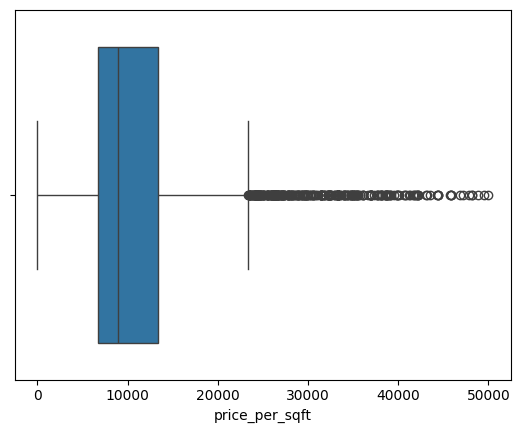

In [23]:
sns.boxplot(x=df['price_per_sqft'])

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\2921252448.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['area'])


<Axes: xlabel='area', ylabel='Density'>

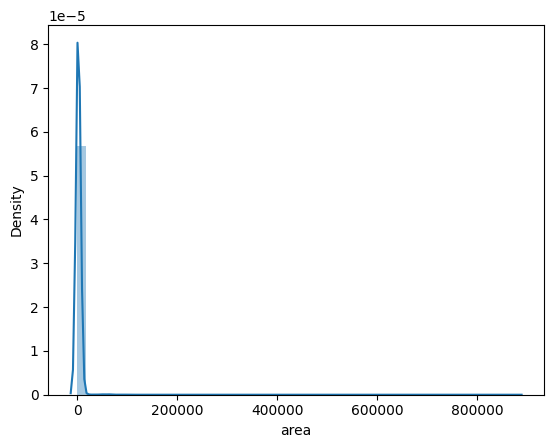

In [24]:
# Area
sns.distplot(df['area'])

<Axes: xlabel='area'>

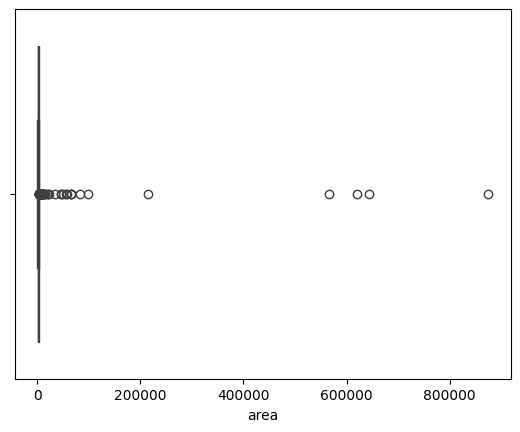

In [25]:
sns.boxplot(x=df['area'])

In [27]:
df[df['area'] > 10000].sort_values('area',ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
3695,flat,hcbs sports ville,sohna road,0.350,4.0,875000.0,Built Up area: 737147 (68483.2 sq.m.),2,2,2,8.0,NaN,Relatively New,NaN,737147.0,NaN,0,0,0,0,0,1,44,5
3460,flat,signature the roselia,sector 95,0.450,7.0,642857.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,2.0,South-West,New Property,NaN,NaN,569243.00,0,0,0,0,0,0,76,12
3210,flat,ramsons kshitij,sector 95,0.310,5.0,620000.0,Carpet area: 607936 (56479.1 sq.m.),2,2,1,1.0,North-East,Relatively New,NaN,NaN,607936.00,0,1,0,0,1,0,65,5
1528,flat,signature global solera 2,sector 107,0.510,9.0,566667.0,Carpet area: 514396 (47788.95 sq.m.),2,2,1,3.0,North,New Property,NaN,NaN,514396.00,0,0,0,0,0,0,44,3
948,house,independent,sector 50,5.000,232.0,215517.0,Plot area 2(1011.71 sq.m.),6,5,3+,2.0,NaN,New Property,NaN,2.0,NaN,1,1,1,0,1,0,0,45
3333,house,independent,sector 26,18.400,1859.0,98978.0,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3+,4.0,South,Relatively New,NaN,NaN,11000.00,1,0,1,1,0,1,60,46
3413,house,ganpati heights apartment,sector 13,1.250,151.0,82781.0,Plot area 115(7692.86 sq.m.),10,6,2,3.0,South-East,Old Property,NaN,115.0,NaN,0,0,0,0,1,0,7,50
2159,flat,rof ananda,sector 95,0.380,58.0,65517.0,Carpet area: 64412 (5984.07 sq.m.),3,2,1,12.0,North,Relatively New,NaN,NaN,64412.00,0,0,0,0,0,0,51,15
3425,house,dlf city plot phase 4,sector 28,13.000,1992.0,65261.0,Carpet area: 7250 (6061.92 sq.m.),10,10,3+,1.0,NaN,Undefined,NaN,NaN,7250.00,0,0,0,0,0,0,0,47
2137,flat,rof ananda,sector 95,0.375,58.0,64655.0,Carpet area: 64529 (5994.94 sq.m.),2,2,2,10.0,East,New Property,NaN,NaN,64529.00,0,1,0,0,0,0,15,15


In [28]:
df.drop(index=[3695,3460,3210,1528,948,1747,1263,1854,976,2137,804,2159,1506], inplace=True)

In [29]:
df[df['area'] > 10000].sort_values('area',ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
3333,house,independent,sector 26,18.40,1859.0,98978.0,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3+,4.0,South,Relatively New,NaN,NaN,11000.00,1,0,1,1,0,1,60,46
3413,house,ganpati heights apartment,sector 13,1.25,151.0,82781.0,Plot area 115(7692.86 sq.m.),10,6,2,3.0,South-East,Old Property,NaN,115.0,NaN,0,0,0,0,1,0,7,50
3425,house,dlf city plot phase 4,sector 28,13.00,1992.0,65261.0,Carpet area: 7250 (6061.92 sq.m.),10,10,3+,1.0,NaN,Undefined,NaN,NaN,7250.00,0,0,0,0,0,0,0,47
2602,house,independent,sector 25,7.30,1560.0,46795.0,Plot area 215(179.77 sq.m.)Built Up area: 5800...,9,9,2,3.0,North-West,Relatively New,NaN,5800.0,5200.00,0,0,1,1,0,0,109,44
2021,house,independent,sector 57,6.25,2778.0,22498.0,Plot area 3100(2591.99 sq.m.)Built Up area: 26...,9,9,3+,3.0,North-East,New Property,NaN,2660.0,2500.00,0,0,1,0,0,1,61,49
1119,house,independent,sector 43,5.50,2716.0,20250.0,Plot area 215(179.77 sq.m.)Built Up area: 2850...,8,7,3+,3.0,East,Moderately Old,NaN,2850.0,2250.00,1,1,1,0,1,1,123,47
1036,flat,godrej air,sector 85,2.50,1379.0,18129.0,Carpet area: 18122 (1683.59 sq.m.),4,5,3+,16.0,North-East,Undefined,NaN,NaN,18122.00,1,1,0,0,1,0,44,8
2896,house,unitech aspen greens,sector 50,6.95,4490.0,15479.0,Plot area 240(200.67 sq.m.)Built Up area: 2160...,3,3,1,2.0,North-East,Moderately Old,NaN,2160.0,1720.00,0,0,1,0,0,0,160,45
1061,house,independent,sector 4,0.85,630.0,13492.0,Plot area 1500(1254.19 sq.m.),3,3,1,1.0,North,Relatively New,NaN,13500.0,NaN,0,0,0,0,1,0,0,49
2981,flat,godrej icon,sector 88a,1.75,1384.0,12645.0,Carpet area: 1175.11,3,3,3+,6.0,NaN,New Property,NaN,NaN,1175.11,0,0,0,0,0,0,55,15


In [30]:
df.loc[3413,'area'] = 115*9
df.loc[3425,'area'] = 7250
df.loc[2602,'area'] = 5800
df.loc[2021,'area'] = 2660
df.loc[1119,'area'] = 2850
df.loc[1036,'area'] = 1812
df.loc[2896,'area'] = 2160
df.loc[2981,'area'] = 1175

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\91062565.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['area'])


<Axes: xlabel='area', ylabel='Density'>

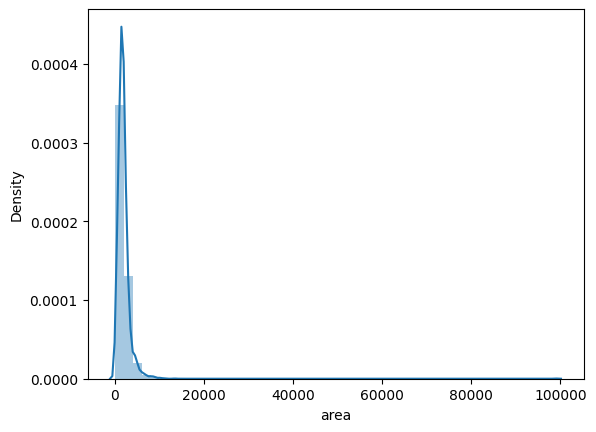

In [31]:
sns.distplot(df['area'])

<Axes: xlabel='area'>

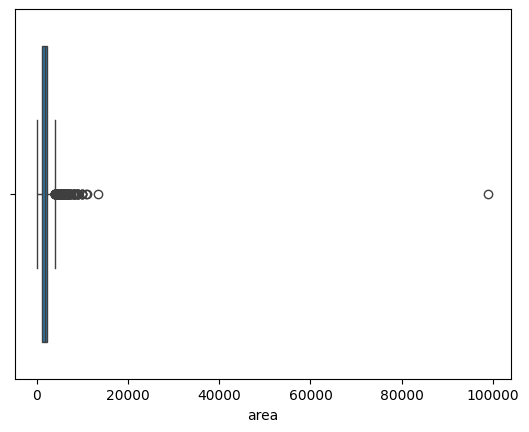

In [32]:
sns.boxplot(x=df['area'])

In [33]:
df[df['area'] > 40000].sort_values('area',ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
3333,house,independent,sector 26,18.4,1859.0,98978.0,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3+,4.0,South,Relatively New,NaN,NaN,11000.0,1,0,1,1,0,1,60,46


In [34]:
df.drop(index=3333,inplace=True)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\91062565.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['area'])


<Axes: xlabel='area', ylabel='Density'>

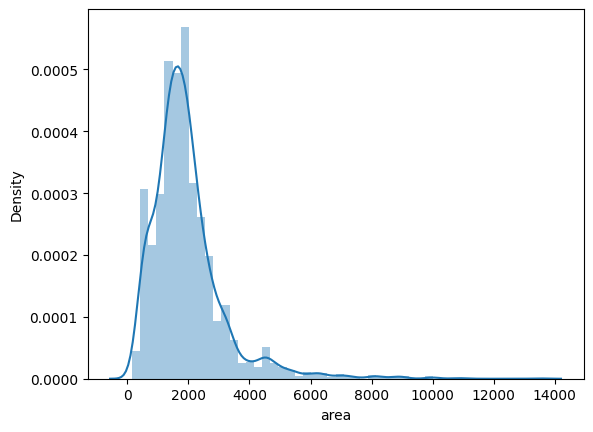

In [35]:
sns.distplot(df['area'])

<Axes: xlabel='area'>

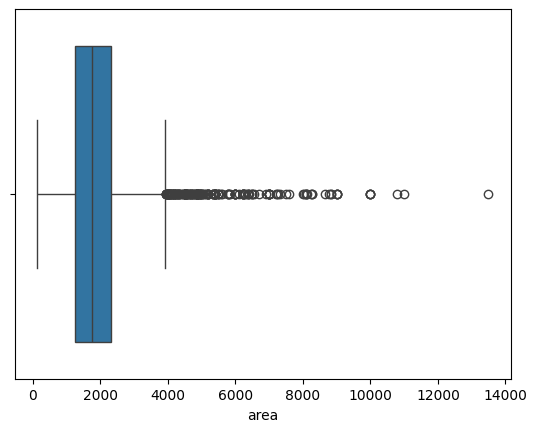

In [36]:
sns.boxplot(x=df['area'])

In [37]:
df['area'].describe()

count     3634.000000
mean      1950.353330
std       1219.448501
min        145.000000
25%       1261.000000
50%       1746.500000
75%       2325.000000
max      13492.000000
Name: area, dtype: float64

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\1604692785.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bedRoom'])


<Axes: xlabel='bedRoom', ylabel='Density'>

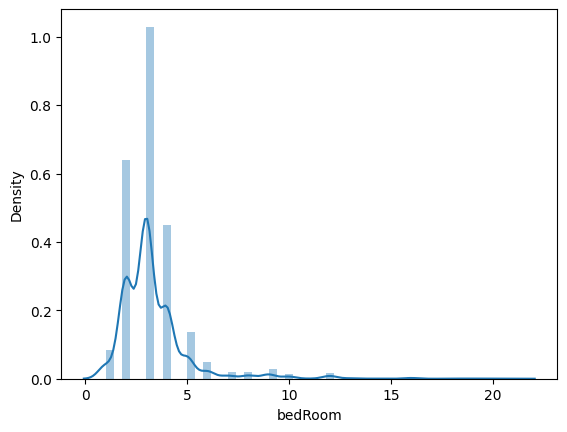

In [38]:
# BedRoom
sns.distplot(df['bedRoom'])

<Axes: xlabel='bedRoom'>

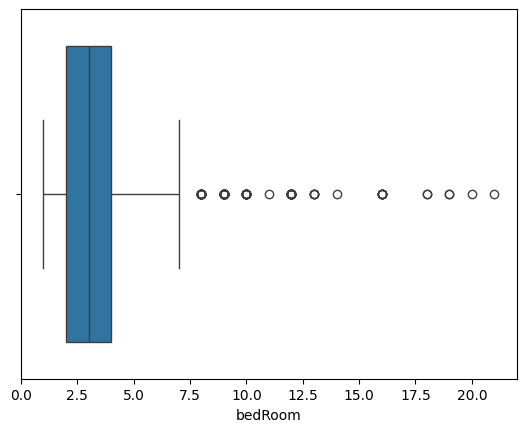

In [39]:
sns.boxplot(x=df['bedRoom'])

In [40]:
df['bedRoom'].describe()

count    3634.000000
mean        3.332141
std         1.829214
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        21.000000
Name: bedRoom, dtype: float64

In [41]:
df[df['bedRoom'] > 10].sort_values('bedRoom',ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
3724,house,independent,sector 54,5.00,43066.0,1161.0,Plot area 129(107.86 sq.m.),21,21,3+,5.0,North,Relatively New,NaN,1161.0,NaN,0,0,1,0,0,1,49,44
3440,house,independent,sector 43,4.50,39062.0,1152.0,Plot area 128(107.02 sq.m.),20,20,3+,4.0,East,Relatively New,NaN,1152.0,NaN,0,0,1,0,0,1,22,47
1357,house,independent,sector 17a,3.93,24214.0,1623.0,Plot area 1623(150.78 sq.m.)Built Up area: 162...,19,17,3,4.0,North-West,Relatively New,NaN,1622.0,NaN,1,1,1,1,0,0,74,48
2581,house,independent,sector 17a,3.87,5160.0,7500.0,Plot area 1623(150.78 sq.m.)Built Up area: 750...,19,17,3+,5.0,North-West,Relatively New,NaN,7500.0,NaN,0,1,0,1,0,0,68,48
532,house,private house,sector 55,7.05,46906.0,1503.0,Plot area 167(139.63 sq.m.),18,18,3+,4.0,North-East,Relatively New,NaN,1503.0,NaN,0,0,0,0,1,2,57,48
2472,house,independent,sector 54,5.50,38194.0,1440.0,Plot area 160(133.78 sq.m.),18,18,3+,4.0,South-West,Relatively New,NaN,1440.0,NaN,0,0,1,0,0,1,70,47
1782,house,independent,sector 55,9.19,34037.0,2700.0,Plot area 300(250.84 sq.m.),16,18,2,4.0,West,New Property,NaN,2700.0,NaN,1,0,1,0,0,0,49,48
1593,house,independent,sector 11,4.50,25000.0,1800.0,Plot area 200(167.23 sq.m.),16,16,3+,4.0,South,Relatively New,NaN,1800.0,NaN,0,0,0,0,0,1,20,50
1741,house,dlf city plots,sector 26,20.00,44267.0,4518.0,Plot area 502(419.74 sq.m.),16,20,3+,4.0,North-East,New Property,NaN,4518.0,NaN,1,1,1,1,0,1,153,8
1118,house,independent,sector 40,12.00,38986.0,3078.0,Plot area 342(285.96 sq.m.),16,16,3+,4.0,NaN,New Property,NaN,3078.0,NaN,1,1,1,1,0,1,0,48


In [42]:
df = df[df['bedRoom'] <= 10]

In [43]:
df.shape

(3589, 24)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\1691983684.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bedRoom'])


<Axes: xlabel='bedRoom', ylabel='Density'>

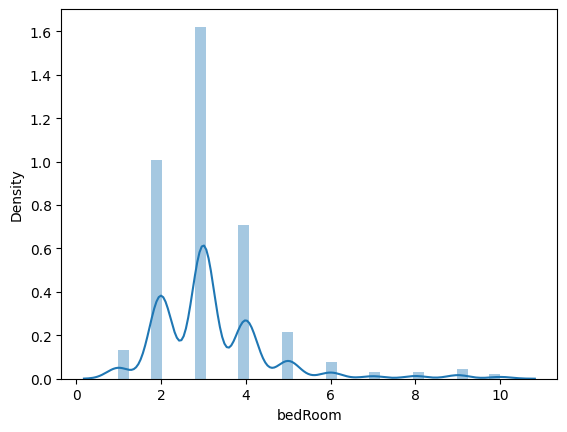

In [44]:
sns.distplot(df['bedRoom'])

<Axes: xlabel='bedRoom'>

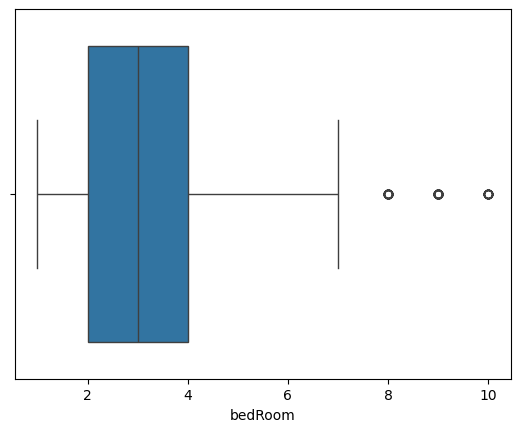

In [45]:
sns.boxplot(x=df['bedRoom'])

In [46]:
df['bedRoom'].describe()

count    3589.000000
mean        3.202285
std         1.392881
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        10.000000
Name: bedRoom, dtype: float64

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\1890980366.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bathroom'])


<Axes: xlabel='bathroom', ylabel='Density'>

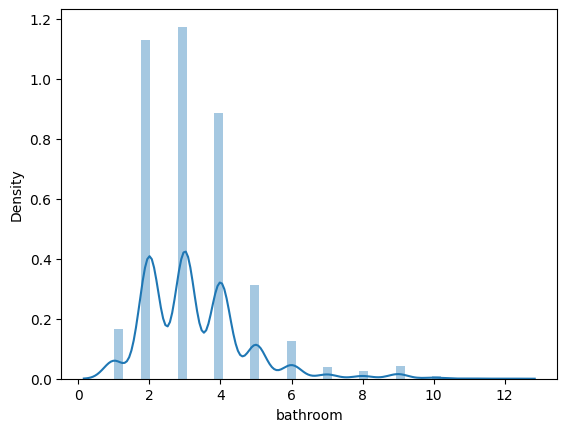

In [47]:
# Bathroom
sns.distplot(df['bathroom'])

<Axes: xlabel='bathroom'>

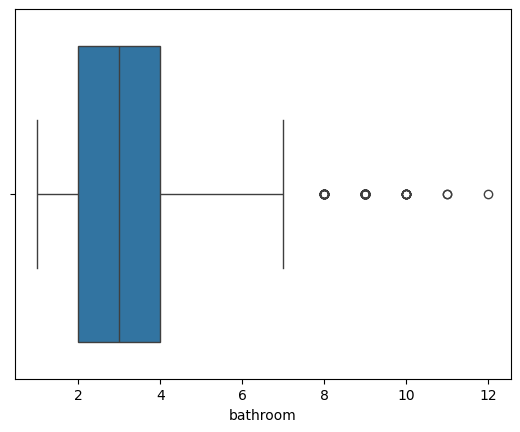

In [48]:
sns.boxplot(x=df['bathroom'])

In [49]:
df[df['bathroom'] > 10].sort_values('bathroom',ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
2541,house,adani brahma samsara,sector 60,18.02,28200.0,6390.0,Built Up area: 6390 (593.65 sq.m.),9,12,3+,3.0,North-East,Relatively New,NaN,6390.0,NaN,0,0,1,0,0,0,146,12
671,house,independent,sector 24,11.00,28902.0,3806.0,Plot area 3806.45(353.63 sq.m.)Built Up area: ...,8,11,3+,3.0,East,Old Property,NaN,5000.0,NaN,1,1,1,0,1,1,39,0
3184,house,independent,sector 39,7.00,10000.0,7000.0,Plot area 350(32.52 sq.m.)Built Up area: 7000 ...,10,11,3+,4.0,South-East,Relatively New,NaN,7000.0,NaN,1,0,0,0,0,1,38,49


In [50]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up a...,2,2,2,5.0,NaN,Relatively New,567.0,556.0,500.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,8.0,West,Moderately Old,NaN,NaN,2400.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,3,3+,17.0,South-East,Relatively New,1930.0,1700.0,1500.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up...,3,3,3+,7.0,South,Old Property,2000.0,1900.0,1800.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,15.0,North,Relatively New,NaN,NaN,1326.0,0,0,0,0,0,1,44,8


C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\1993728394.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['super_built_up_area'])


<Axes: xlabel='super_built_up_area', ylabel='Density'>

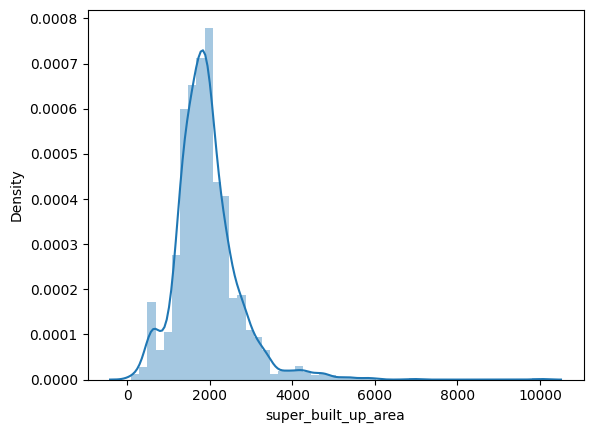

In [51]:
# Super_built_up_area
sns.distplot(df['super_built_up_area'])

<Axes: ylabel='super_built_up_area'>

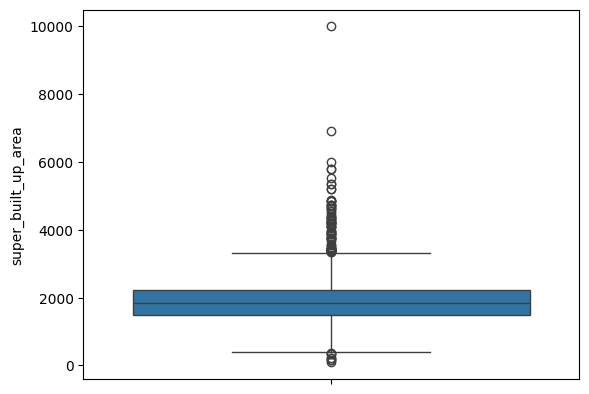

In [52]:
sns.boxplot(df['super_built_up_area'])

In [53]:
df['super_built_up_area'].describe()

count     1876.000000
mean      1924.557862
std        764.535501
min         89.000000
25%       1478.750000
50%       1828.000000
75%       2215.000000
max      10000.000000
Name: super_built_up_area, dtype: float64

In [54]:
df[df['super_built_up_area'] > 6000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
824,flat,krrish provence estate,gwal pahari,7.5,7500.0,10000.0,Super Built up area 10000(929.03 sq.m.),5,6,3+,23.0,North-East,Relatively New,10000.0,NaN,NaN,1,0,1,0,1,0,49,15
1054,flat,bestech park view grand spa,sector 81,4.7,6786.0,6926.0,Super Built up area 6926(643.45 sq.m.),4,4,3+,19.0,North,Relatively New,6926.0,NaN,NaN,0,0,1,0,0,0,140,10


C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\2302651318.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['built_up_area'])


<Axes: xlabel='built_up_area', ylabel='Density'>

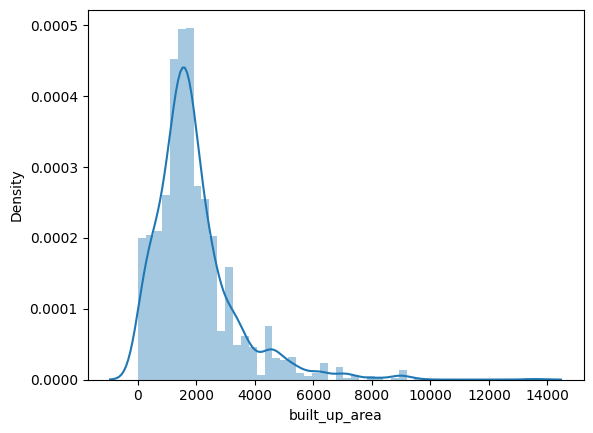

In [55]:
# built_up_area
sns.distplot(df['built_up_area'])

<Axes: xlabel='built_up_area'>

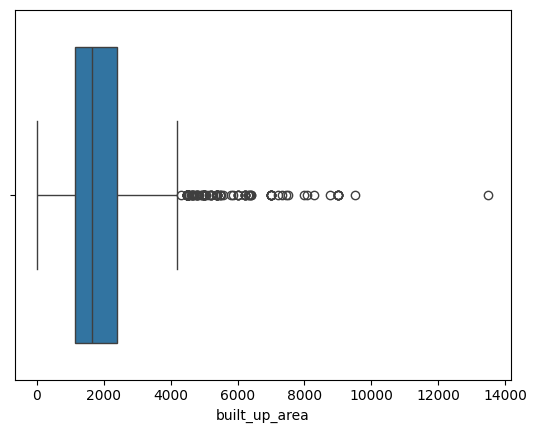

In [56]:
sns.boxplot(x=df['built_up_area'])

In [57]:
df[df['built_up_area'] > 10000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
1061,house,independent,sector 4,0.85,630.0,13492.0,Plot area 1500(1254.19 sq.m.),3,3,1,1.0,North,Relatively New,NaN,13500.0,NaN,0,0,0,0,1,0,0,49


C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\2977382181.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['carpet_area'])


<Axes: xlabel='carpet_area', ylabel='Density'>

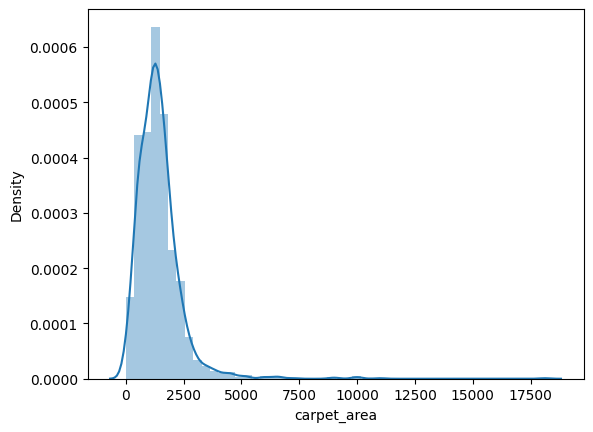

In [58]:
# carpet_area
sns.distplot(df['carpet_area'])

<Axes: xlabel='carpet_area'>

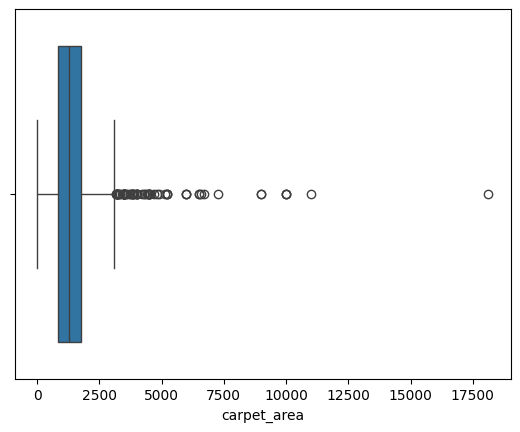

In [59]:
sns.boxplot(x=df['carpet_area'])

In [60]:
df[df['carpet_area'] > 10000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
1036,flat,godrej air,sector 85,2.5,1379.0,1812.0,Carpet area: 18122 (1683.59 sq.m.),4,5,3+,16.0,North-East,Undefined,NaN,NaN,18122.0,1,1,0,0,1,0,44,8
1563,flat,m3m golfestate,sector 65,13.2,12000.0,11000.0,Carpet area: 11000 (1021.93 sq.m.),4,4,3,13.0,North,Moderately Old,NaN,NaN,11000.0,0,0,1,0,0,0,60,9


In [61]:
df.loc[1036,'carpet_area'] = 1812

In [62]:
df[df['carpet_area'] > 10000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
1563,flat,m3m golfestate,sector 65,13.2,12000.0,11000.0,Carpet area: 11000 (1021.93 sq.m.),4,4,3,13.0,North,Moderately Old,NaN,NaN,11000.0,0,0,1,0,0,0,60,9


In [63]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up a...,2,2,2,5.0,NaN,Relatively New,567.0,556.0,500.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,8.0,West,Moderately Old,NaN,NaN,2400.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,3,3+,17.0,South-East,Relatively New,1930.0,1700.0,1500.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up...,3,3,3+,7.0,South,Old Property,2000.0,1900.0,1800.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,15.0,North,Relatively New,NaN,NaN,1326.0,0,0,0,0,0,1,44,8


C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\3385064764.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['luxury_score'])


<Axes: xlabel='luxury_score', ylabel='Density'>

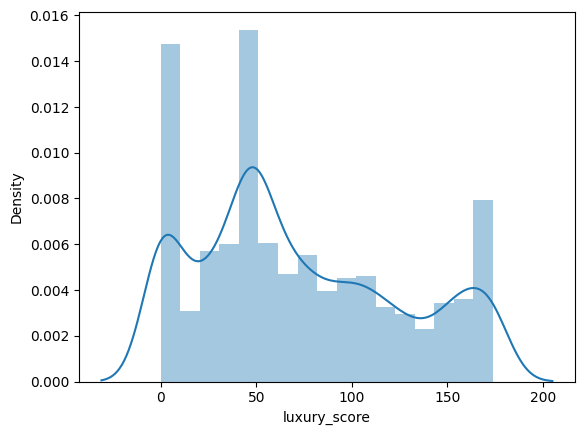

In [64]:
sns.distplot(df['luxury_score'])

<Axes: ylabel='luxury_score'>

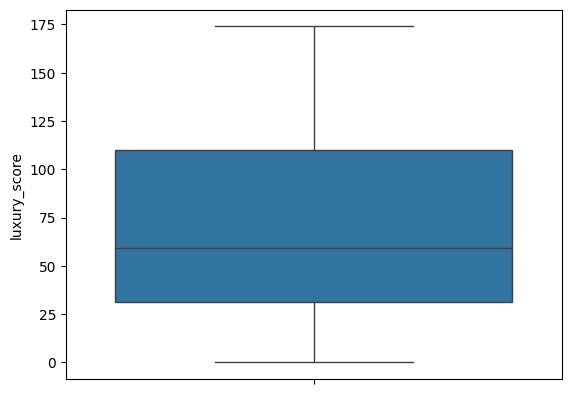

In [65]:
sns.boxplot(df['luxury_score'])

In [66]:
df.shape

(3589, 24)

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\3938633405.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['NearbyLocationsCount'])


<Axes: xlabel='NearbyLocationsCount', ylabel='Density'>

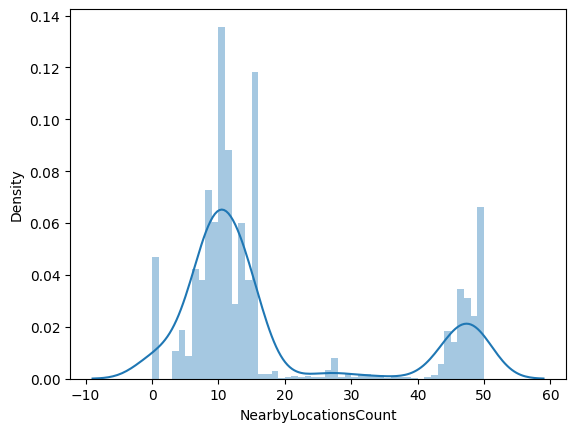

In [67]:
sns.distplot(df['NearbyLocationsCount'])

<Axes: ylabel='NearbyLocationsCount'>

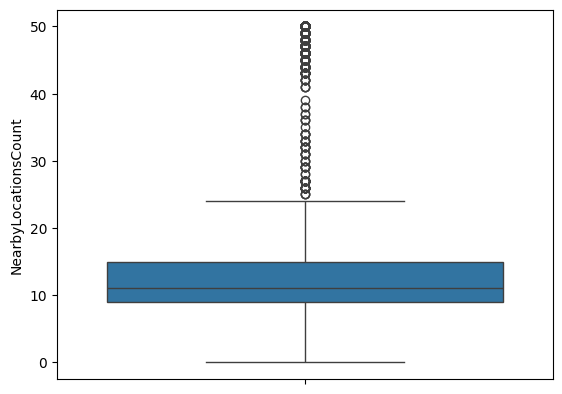

In [68]:
sns.boxplot(df['NearbyLocationsCount'])

In [70]:
df[df['NearbyLocationsCount'] > 40].shape

(707, 24)

In [71]:
df['price_per_sqft'] = round((df['price']*10000000)/df['area'])

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\2186227091.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

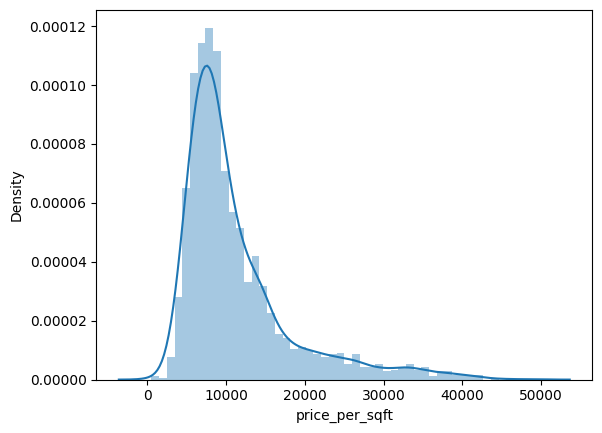

In [72]:
sns.distplot(df['price_per_sqft'])

<Axes: ylabel='price_per_sqft'>

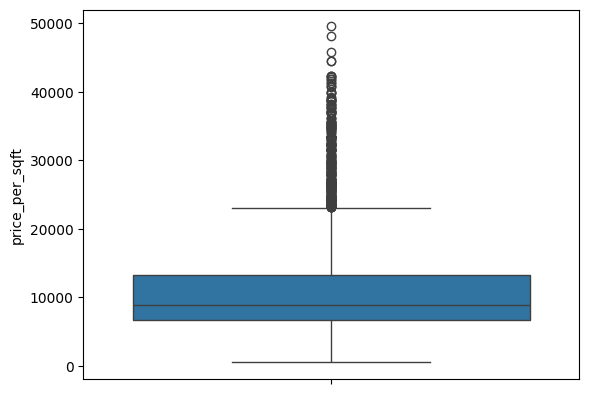

In [73]:
sns.boxplot(df['price_per_sqft'])

In [74]:
df[df['price_per_sqft'] > 42000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
169,house,independent,sector 25,13.0,45710.0,2844.0,Plot area 316(264.22 sq.m.),6,8,3+,NaN,NaN,Relatively New,NaN,2844.0,NaN,1,1,1,1,0,1,0,49
491,house,independent,sector 43,9.5,42222.0,2250.0,Plot area 302(252.51 sq.m.)Built Up area: 300 ...,5,5,3+,2.0,North-East,Relatively New,NaN,300.0,250.0,1,0,1,0,0,1,88,47
558,house,independent,sector 55,5.0,44444.0,1125.0,Plot area 125(104.52 sq.m.)Built Up area: 115 ...,9,9,3+,5.0,East,New Property,NaN,115.0,100.0,0,0,0,0,1,1,44,42
1187,house,independent,sector 28,12.0,42194.0,2844.0,Plot area 316(264.22 sq.m.),4,5,3+,4.0,East,Relatively New,NaN,2844.0,NaN,1,0,1,1,0,0,60,47
2077,house,independent,sector 26,19.0,42222.0,4500.0,Plot area 500(418.06 sq.m.),6,8,3+,3.0,East,Moderately Old,NaN,4500.0,NaN,1,1,1,1,0,0,103,46
3088,house,dlf city plots,sector 26,19.0,42054.0,4518.0,Plot area 502(419.74 sq.m.),6,6,3,2.0,East,Relatively New,NaN,4518.0,NaN,0,1,1,0,0,0,121,8
3256,house,sushant lok 1 builder floors,sector 43,13.0,48148.0,2700.0,Plot area 300(250.84 sq.m.),3,3,3+,4.0,North,New Property,NaN,2700.0,NaN,1,0,0,0,0,0,7,47
3371,house,independent,sector 105,9.9,49500.0,2000.0,Built Up area: 2000 (185.81 sq.m.)Carpet area:...,2,2,2,3.0,North,Undefined,NaN,2000.0,1800.0,0,0,0,0,0,0,0,33
3685,house,independent,sector 26,20.0,44444.0,4500.0,Plot area 500(418.06 sq.m.),5,7,3+,3.0,West,Relatively New,NaN,4500.0,NaN,1,0,1,0,0,1,97,46


In [75]:
x = df[df['price_per_sqft'] <= 20000]
(x['area']/x['bedRoom']).quantile(0.02)

np.float64(186.06)

In [76]:
df[(df['area']/df['bedRoom'])<186]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
16,house,independent,sector 13,0.90,11465.0,785.0,Plot area 785(72.93 sq.m.),5,4,3,3.0,North-West,Moderately Old,NaN,785.0,NaN,1,1,1,0,1,0,0,50
39,house,independent,sector 105,1.20,13333.0,900.0,Plot area 900(83.61 sq.m.),7,4,1,2.0,South-West,Moderately Old,NaN,900.0,NaN,0,0,0,0,1,0,14,31
68,house,housing board colony,sector 28,2.10,23333.0,900.0,Plot area 100(83.61 sq.m.),8,8,3+,4.0,South-East,Moderately Old,NaN,900.0,NaN,0,0,0,0,1,0,38,48
145,house,independent,sector 105,0.60,13333.0,450.0,Built Up area: 450 (41.81 sq.m.),3,3,0,3.0,NaN,Undefined,NaN,450.0,NaN,0,0,0,0,0,0,0,33
189,house,independent,sector 6,0.50,13889.0,360.0,Plot area 40(33.45 sq.m.),5,3,3,3.0,NaN,Old Property,NaN,360.0,NaN,0,0,0,0,0,0,0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3436,house,sheetla enclave,sector 5,0.96,10000.0,960.0,Plot area 945(87.79 sq.m.),7,4,2,3.0,NaN,Moderately Old,NaN,945.0,NaN,1,0,0,1,0,0,0,49
3473,house,independent,sector 104,0.60,5128.0,1170.0,Plot area 130(108.7 sq.m.),7,3,1,2.0,North,Moderately Old,NaN,1170.0,NaN,0,0,0,0,0,0,0,50
3587,house,sector 38 rwa,sector 38,1.40,23932.0,585.0,Plot area 65(54.35 sq.m.)Built Up area: 62 sq....,8,8,3,4.0,East,Moderately Old,NaN,62.0,60.0,0,0,0,0,1,1,40,47
3641,house,independent,sector 6,0.75,10519.0,713.0,Plot area 713(66.24 sq.m.),6,4,1,3.0,NaN,Moderately Old,NaN,713.0,NaN,0,0,0,0,0,0,62,50


In [77]:
df[(df['area']/df['bedRoom'])<186].shape

(78, 24)

In [92]:
x = df[df['price_per_sqft'] <= 20000]
(x['area']/x['bedRoom']).quantile(0.05)

np.float64(261.625)

In [93]:
df[(df['area']/df['bedRoom'])<261].sample(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,area_room_ratio
158,flat,mvn athens,sohna road,0.26,5394.0,482.0,Carpet area: 481.73 (44.75 sq.m.),2,2,1,5.0,NaN,Relatively New,NaN,NaN,481.684525,0,0,0,0,0,0,95,10,241.000000
701,house,independent,sector 4,0.67,9795.0,684.0,Plot area 76(7.06 sq.m.),3,3,2,2.0,South,Relatively New,NaN,76.0,NaN,0,0,0,0,1,0,7,49,228.000000
669,flat,gls arawali homes,sohna road,0.30,6237.0,481.0,Super Built up area 567(52.68 sq.m.)Carpet are...,2,2,2,4.0,East,Relatively New,567.0,NaN,480.530000,0,0,0,0,0,1,120,6,240.500000
1933,flat,central park flower valley,sector 33,1.40,21538.0,650.0,Super Built up area 650(60.39 sq.m.),3,3,3,2.0,NaN,Under Construction,650.0,NaN,NaN,0,0,0,0,0,0,54,11,216.666667
1666,house,independent,sector 2,1.15,19360.0,594.0,Plot area 66(55.18 sq.m.),3,3,2,2.0,South-East,Old Property,NaN,594.0,NaN,0,0,0,0,0,0,32,27,198.000000


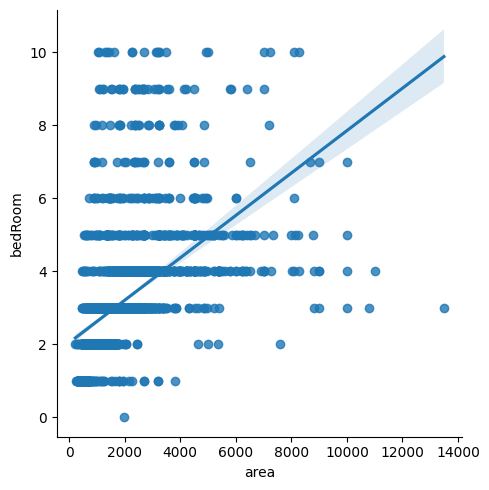

In [94]:
sns.lmplot(data=df,x='area',y='bedRoom')

In [95]:
df['area_room_ratio'] = df['area']/df['bedRoom']

In [98]:
(df[df['area_room_ratio'] < 261])['bedRoom'].value_counts()

bedRoom
2     58
3     41
5     20
6     18
4     12
9     11
10     8
8      8
7      6
1      1
Name: count, dtype: int64

In [97]:
df = df[df['area_room_ratio'] > 100]

In [102]:
outliers_df = df[(df['area_room_ratio'] < 261) & (df['bedRoom'] > 3)]

In [103]:
outliers_df['bedRoom'] = round(outliers_df['bedRoom']/outliers_df['floorNum'])

C:\Users\THARUN TEJA S\AppData\Local\Temp\ipykernel_5704\3450078040.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_df['bedRoom'] = round(outliers_df['bedRoom']/outliers_df['floorNum'])


In [104]:
df.update(outliers_df)

In [105]:
df['area_room_ratio'] = df['area']/df['bedRoom']

In [106]:
df[(df['area_room_ratio'] < 261) & (df['bedRoom'] > 4)]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,area_room_ratio
281,house,independent,sector 11,3.50,15556.0,2250.0,Built Up area: 2250 (209.03 sq.m.),10,1,0,1.0,NaN,New Property,NaN,2250.0,NaN,0,0,0,0,0,0,0,50,225.000000
359,house,shivpuri,sector 7,2.80,12444.0,2250.0,Plot area 2250(209.03 sq.m.),10,7,3,1.0,NaN,Old Property,NaN,2250.0,NaN,1,1,1,0,1,1,0,50,225.000000
759,house,independent,manesar,0.80,6667.0,1200.0,Plot area 1200(111.48 sq.m.),8,8,2,1.0,NaN,Relatively New,NaN,1200.0,NaN,0,0,0,0,0,0,0,18,150.000000
859,house,independent,sector 12,2.50,13889.0,1800.0,Plot area 1800(167.23 sq.m.),9,5,2,1.0,South-East,Old Property,NaN,1800.0,NaN,1,0,0,0,0,0,8,50,200.000000
953,house,independent,sector 11,0.95,7308.0,1300.0,Built Up area: 1300 (120.77 sq.m.),5,3,0,1.0,NaN,Undefined,NaN,1300.0,NaN,0,0,0,0,0,0,0,0,260.000000
1365,house,independent,sector 2,0.98,9074.0,1080.0,Carpet area: 120 (100.34 sq.m.),9,4,3,1.0,South,Undefined,NaN,NaN,120.0,0,0,0,0,0,0,0,0,120.000000
1672,house,independent,sector 3 phase 2,1.10,10000.0,1100.0,Built Up area: 1100 (102.19 sq.m.)Carpet area:...,5,4,2,1.0,East,Undefined,NaN,1100.0,900.0,0,0,0,0,0,0,0,0,220.000000
2802,house,independent,sector 17,0.32,5664.0,565.0,Built Up area: 565 (52.49 sq.m.),5,1,0,1.0,NaN,Undefined,NaN,565.0,NaN,0,0,0,0,0,0,0,0,113.000000
2845,house,independent,sector 105,1.10,12222.0,900.0,Carpet area: 900 (83.61 sq.m.),6,4,1,1.0,South-West,Undefined,NaN,NaN,900.0,0,0,0,0,0,0,0,0,150.000000
2923,house,independent,sector 7,1.16,11717.0,990.0,Carpet area: 110 (91.97 sq.m.),5,4,2,1.0,North-East,Undefined,NaN,NaN,110.0,0,0,0,0,0,0,0,0,198.000000


In [107]:
df[(df['area_room_ratio'] < 261) & (df['bedRoom'] > 4)].shape

(14, 25)

In [110]:
df = df[~((df['area_room_ratio'] < 261) & (df['bedRoom'] > 4))]

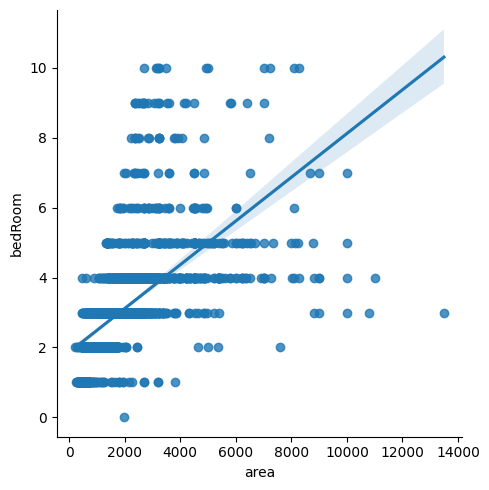

In [111]:
sns.lmplot(data=df,x='area',y='bedRoom')

In [112]:
df.to_csv('Final_outlier_treated_data.csv',index=True)